In [41]:
import numpy as np
import matplotlib.pyplot as plt

In [42]:
#Konstanten/ feste Werte
g = 9.81
rho_öl_15 = 877 # Dichte von Öl bei 288.15 Kelvin
rho_öl_25 = 871 # Dichte von Öl bei 298.15 Kelvin, war ehr bei uns gegeben

eta_20 = 1.819e-05 # Viskosität der Luft bei 293.15K, diese Raumtemperatur hatten wir in etwa
eta_26_85 = 1.86e-05 # Viskosität der Luft bei 300K
eta_30 = 1.867e-05 # Viskosität der Luft bei 303.15K

e = 1.6e-19

In [43]:
def std(a):
    mittelwert = np.mean(a)
    temp = 0
    for i in range(0,len(a)):
        temp = temp + (a[i]-mittelwert)**2
    u = np.sqrt(temp/(len(a)-1))
    return u

In [44]:
# Testen der Fkt. std
werte = [1, 2, 3]
print(len(werte))

print(std(werte))

3
1.0


# Auswertung des Versuchs

In [45]:
#Einpflegen der Daten

# gemessene Zeiten am ersten Okula 
t_1_fall = [32.61, 33.4, 31.98, 32.23, 34.01]
t_1_steig = [15.12, 13.01, 13.26, 12.47, 11.5]
t_1_U = 461

# gemessene Zeiten am zweiten Okula
t_2_fall = [19.5, 16.08, 30.49, 28.28, 28.6]
t_2_steig = [7.99, 12.31, 12.63, 13.41, 11.69]
t_2_U = 597 #Spannung schwankte zwischen 597 und 598 hin und her 
 
t_3_fall = [28.02, 24.98, 23.36, 22.85, 19.93]
t_3_steig = [16.43, 15.44, 14.08, 15.98, 13.80]
t_3_U = 598

t_4_fall = [23.36, 21.91, 25.06, 29.49, 31.69]
t_4_steig = [15.68, 16, 15.92, 16.85, 15.17]
t_4_U = 481

t_5_fall = [17.81, 23.02, 19.23, 17.35, 18.87]
t_5_steig = [9.93, 7.46, 6.97, 5.71, 7.11]
t_5_U = 598

t_6_fall = [34.73, 35.84, 35.22, 30.28, 32.8]
t_6_steig = [11.49, 12.84, 11.10, 12.01, 13.11]
t_6_U = 597

t_7_fall = [13.95, 14.63, 18.32, 17.8, 14.64]
t_7_steig = [12.47, 11.03, 10.78, 15.21, 10.45]
t_7_U = 597

t_8_fall = [20.95, 27.46, 35.08, 32.68, 29.71]
t_8_steig = [8.08, 10.13, 9.86, 9.62, 9.34]
t_8_U = 598

t_9_fall = [24.74, 26.57, 26.88, 24.70, 20.94]
t_9_steig = [16.23, 13.54, 11.22, 8.47, 7.81]
t_9_U = 598

# gemessene Zeiten für das dritte Okula

t_10_fall = [16.78, 35.76, 26.38, 25.99, 28.43]
t_10_steig = [12.82, 12.40, 13.32, 14.78, 14.28]
t_10_U = 558

t_11_fall = [37.72, 36.72, 38.9, 29.23, 27.46]
t_11_steig = [10.33, 10.6, 10.25, 14.06, 13.47]
t_11_U = 545

# Spannungen in ein Array einbetten
t_i_U = [t_1_U, t_2_U, t_3_U, t_4_U, t_5_U, t_6_U, t_7_U, t_8_U, t_9_U, t_10_U, t_11_U]

## Gesamt Auswertung
### Auswertung: Berechnung der Geschwindigkeiten (Theorie)

    - für jedes Öltröpfchen den Mittelwert und Unsicherheit von Steig- und Fallzeit bestimmen
        - Studentische T Verteilung weil nur 5 Werte
            - u_{corr}(x) = t_p(v)*u(x) mit t_p(v) = 1,14

    - Unsicherheiten 
        - in der Stoppuhr -> +/- 0.005 (Rechtecksverteilung)
        - Reaktionszeit -> 0,14 s
        -> Unsicherheiten in Stoppuhrunsicherheit und Reaktionszeit sind direkte kombinierte Unsicherheiten, also Unsicherheit für die                  gemessene Zeit: u_t = \sqrt{u_{reaktionszeit}^2 + u_{stoppuhr}^2}
        - Zurückgelegte Strecke -> +/- 0,05 mm = +/- 0,00005 m
                - da wird insgesamt die Geschwindigkeit v bestimmen wollen, müssen wir noch die Fehlerfortpflanzung machen                       da v = \frac{s}{t} ist 
    -> am Ende haben wir hier von die Geschwindigkeit Hoch und Runter
      

#### Fehlerfortpflanzung Geschwindigkeit
$$
v = \frac{s}{t}
$$


$$
u_v(s,t)= \sqrt{\left(\frac{u_s}{t}\right)^2 + \left(-\frac{s*u_t}{t^2}\right)^2}*t_p
$$

### Auswertung: Berechnung der Geschwindigkeiten(Praxis)

In [46]:
"""
Hier: Mittelwert und Standardabweichung Mittelwert (Typ A) berechnen der einzelnen Zeiten der Öltröpfchen (Fall- und Steigzeit), 
unter Berücksichtigung der Studentischen T-Verteilung (t_p = 1.14)
"""
t_p = 1.14

t_1_fall_m = np.mean(t_1_fall)
t_1_fall_un_A= std(t_1_fall)*t_p/np.sqrt(5)
t_1_steig_m = np.mean(t_1_steig)
t_1_steig_un_A= std(t_1_steig)*t_p/np.sqrt(5)

t_2_fall_m = np.mean(t_2_fall)
t_2_fall_un_A= std(t_2_fall)*t_p/np.sqrt(5)
t_2_steig_m = np.mean(t_2_steig)
t_2_steig_un_A= std(t_2_steig)*t_p/np.sqrt(5)

t_3_fall_m = np.mean(t_3_fall) 
t_3_fall_un_A= std(t_3_fall)*t_p/np.sqrt(5)
t_3_steig_m = np.mean(t_3_steig)
t_3_steig_un_A= std(t_3_steig)*t_p/np.sqrt(5)

t_4_fall_m = np.mean(t_4_fall) 
t_4_fall_un_A= std(t_4_fall)*t_p/np.sqrt(5)
t_4_steig_m = np.mean(t_4_steig)
t_4_steig_un_A= std(t_4_steig)*t_p/np.sqrt(5)

t_5_fall_m = np.mean(t_5_fall) 
t_5_fall_un_A= std(t_5_fall)*t_p/np.sqrt(5)
t_5_steig_m = np.mean(t_5_steig)
t_5_steig_un_A= std(t_4_steig)*t_p/np.sqrt(5)

t_6_fall_m = np.mean(t_6_fall) 
t_6_fall_un_A= std(t_6_fall)*t_p/np.sqrt(5)
t_6_steig_m = np.mean(t_6_steig)
t_6_steig_un_A= std(t_6_steig)*t_p/np.sqrt(5)

t_7_fall_m = np.mean(t_7_fall) 
t_7_fall_un_A= std(t_7_fall)*t_p/np.sqrt(5)
t_7_steig_m = np.mean(t_7_steig)
t_7_steig_un_A= std(t_7_steig)*t_p/np.sqrt(5)

t_8_fall_m = np.mean(t_8_fall) 
t_8_fall_un_A= std(t_8_fall)*t_p/np.sqrt(5)
t_8_steig_m = np.mean(t_8_steig)
t_8_steig_un_A= std(t_8_steig)*t_p/np.sqrt(5)

t_9_fall_m = np.mean(t_9_fall) 
t_9_fall_un_A= std(t_9_fall)*t_p/np.sqrt(5)
t_9_steig_m = np.mean(t_9_steig)
t_9_steig_un_A= std(t_9_steig)*t_p/np.sqrt(5)

t_10_fall_m = np.mean(t_10_fall) 
t_10_fall_un_A= std(t_10_fall)*t_p/np.sqrt(5)
t_10_steig_m = np.mean(t_10_steig)
t_10_steig_un_A= std(t_10_steig)*t_p/np.sqrt(5)

t_11_fall_m = np.mean(t_11_fall) 
t_11_fall_un_A= std(t_11_fall)*t_p/np.sqrt(5)
t_11_steig_m = np.mean(t_11_steig)
t_11_steig_un_A= std(t_11_steig)*t_p/np.sqrt(5)


In [47]:
"""
Gesamte Messunsicherheit (Typ B) für die Zeit, direkte kombinierete Messunsicherheit (Standardunsicherheit der Mittelwerte,
Unsicherheit durch Stoppuhr und Unsicherheit durch Reaktionszeit)
"""
u_stoppuhr = 1.44e-03 # bei abs. Grenzen von 0.005 und einer Rechtecksverteilung
u_reaktion = 2*0.3 #0.14 + 0.18 # einmal akustisch und einmal visuel 

t_1_fall_un_B= np.sqrt(u_stoppuhr**2 + u_reaktion**2)
t_1_steig_un_B = np.sqrt(u_stoppuhr**2 + u_reaktion**2)

t_2_fall_un_B = np.sqrt(u_stoppuhr**2 + u_reaktion**2)
t_2_steig_un_B = np.sqrt(u_stoppuhr**2 + u_reaktion**2)

t_3_fall_un_B = np.sqrt(u_stoppuhr**2 + u_reaktion**2)
t_3_steig_un_B = np.sqrt(u_stoppuhr**2 + u_reaktion**2)

t_4_fall_un_B = np.sqrt(u_stoppuhr**2 + u_reaktion**2)
t_4_steig_un_B = np.sqrt(u_stoppuhr**2 + u_reaktion**2)

t_5_fall_un_B = np.sqrt(u_stoppuhr**2 + u_reaktion**2)
t_5_steig_un_B = np.sqrt(u_stoppuhr**2 + u_reaktion**2)

t_6_fall_un_B = np.sqrt(u_stoppuhr**2 + u_reaktion**2)
t_6_steig_un_B = np.sqrt(u_stoppuhr**2 + u_reaktion**2)

t_7_fall_un_B = np.sqrt(u_stoppuhr**2 + u_reaktion**2)
t_7_steig_un_B = np.sqrt(u_stoppuhr**2 + u_reaktion**2)

t_8_fall_un_B = np.sqrt(u_stoppuhr**2 + u_reaktion**2)
t_8_steig_un_B = np.sqrt(u_stoppuhr**2 + u_reaktion**2)

t_9_fall_un_B = np.sqrt(u_stoppuhr**2 + u_reaktion**2)
t_9_steig_un_B = np.sqrt(u_stoppuhr**2 + u_reaktion**2)

t_10_fall_un_B = np.sqrt(u_stoppuhr**2 + u_reaktion**2)
t_10_steig_un_B = np.sqrt(u_stoppuhr**2 + u_reaktion**2)

t_11_fall_un_B = np.sqrt(u_stoppuhr**2 + u_reaktion**2)
t_11_steig_un_B = np.sqrt(u_stoppuhr**2 + u_reaktion**2)
print(t_11_fall_un_B)
print(t_5_steig_un_B)

0.6000017279975116
0.6000017279975116


In [48]:
"""
Zusammenführen der Unsicherheiten von Typ A und Typ B 
"""
t_1_fall_un = np.sqrt(t_1_fall_un_A**2 + t_1_fall_un_B**2)
t_1_steig_un = np.sqrt(t_1_steig_un_A**2 + t_1_steig_un_B**2)

t_2_fall_un = np.sqrt(t_2_fall_un_A**2 + t_2_fall_un_B**2)
t_2_steig_un = np.sqrt(t_2_steig_un_A**2 + t_2_steig_un_B**2)

t_3_fall_un = np.sqrt(t_3_fall_un_A**2 + t_3_fall_un_B**2)
t_3_steig_un = np.sqrt(t_3_steig_un_A**2 + t_3_steig_un_B**2)

t_4_fall_un = np.sqrt(t_4_fall_un_A**2 + t_4_fall_un_B**2)
t_4_steig_un = np.sqrt(t_4_steig_un_A**2 + t_4_steig_un_B**2)

t_5_fall_un = np.sqrt(t_5_fall_un_A**2 + t_5_fall_un_B**2)
t_5_steig_un = np.sqrt(t_5_steig_un_A**2 + t_5_steig_un_B**2)

t_6_fall_un = np.sqrt(t_6_fall_un_A**2 + t_6_fall_un_B**2)
t_6_steig_un = np.sqrt(t_6_steig_un_A**2 + t_6_steig_un_B**2)

t_7_fall_un = np.sqrt(t_7_fall_un_A**2 + t_7_fall_un_B**2)
t_7_steig_un = np.sqrt(t_7_steig_un_A**2 + t_7_steig_un_B**2)

t_8_fall_un = np.sqrt(t_8_fall_un_A**2 + t_8_fall_un_B**2)
t_8_steig_un = np.sqrt(t_8_steig_un_A**2 + t_8_steig_un_B**2)

t_9_fall_un = np.sqrt(t_9_fall_un_A**2 + t_9_fall_un_B**2)
t_9_steig_un = np.sqrt(t_9_steig_un_A**2 + t_9_steig_un_B**2)

t_10_fall_un = np.sqrt(t_10_fall_un_A**2 + t_10_fall_un_B**2)
t_10_steig_un = np.sqrt(t_10_steig_un_A**2 + t_10_steig_un_B**2)

t_11_fall_un = np.sqrt(t_11_fall_un_A**2 + t_11_fall_un_B**2)
t_11_steig_un = np.sqrt(t_11_steig_un_A**2 + t_11_steig_un_B**2)

print(t_1_steig_m)
print(t_1_steig_un)
print()
print(t_1_fall_m)
print(t_1_fall_un)
print(2)
print(t_2_steig_m)
print(t_2_steig_un)
print()
print(t_2_fall_m)
print(t_2_fall_un)
print(3)
print(t_3_steig_m)
print(t_3_steig_un)
print()
print(t_3_fall_m)
print(t_3_fall_un)
print(4)
print(t_4_steig_m)
print(t_4_steig_un)
print()
print(t_4_fall_m)
print(t_4_fall_un)
print(5)
print(t_5_steig_m)
print(t_5_steig_un)
print()
print(t_5_fall_m)
print(t_5_fall_un)
print(6)
print(t_6_steig_m)
print(t_6_steig_un)
print()
print(t_6_fall_m)
print(t_6_fall_un)
print(7)
print(t_7_steig_m)
print(t_7_steig_un)
print()
print(t_7_fall_m)
print(t_7_fall_un)
print(8)
print(t_8_steig_m)
print(t_8_steig_un)
print()
print(t_8_fall_m)
print(t_8_fall_un)
print(9)
print(t_9_steig_m)
print(t_9_steig_un)
print()
print(t_9_fall_m)
print(t_9_fall_un)
print(10)
print(t_10_steig_m)
print(t_10_steig_un)
print()
print(t_10_fall_m)
print(t_10_fall_un)
print(11)
print(t_11_steig_m)
print(t_11_steig_un)
print()
print(t_11_fall_m)
print(t_11_fall_un)



13.072
0.9051082432504962

32.846
0.7382377226882948
2
11.606
1.2336601035941788

24.589999999999996
3.30771543298392
3
15.145999999999997
0.8423249368266379

23.828000000000003
1.62844676793563
4
15.924000000000001
0.675949737184652

26.302
2.196115808421769
5
7.436
0.675949737184652

19.256
1.289292073659029
6
12.11
0.7426467030829665

33.774
1.2990528377244706
7
11.988
1.1652639838251246

15.868
1.195763767639746
8
9.406
0.7245468233316601

29.176
2.833677686540937
9
11.454
1.8894363940604086

24.766
1.3466222704232982
10
13.52
0.7852687957635905

26.668
3.510241955763163
11
11.742
1.1234431948256218

34.006
2.749165228064693


### Einschub: Durch Unschicherheit in Okular folgt eine Unsicherheit in der Strecke 

Das Okular hat eine Unsicherheit von $\pm 0.05$. Diese Unsicherheit und die durch die Skala sind direkt kombinierte Unsicherheiten. Also
$$
u_s = \sqrt{u_{Skala}^2 + u_{Okular}^2}
$$

In [49]:
s = 0.001 
u_skala = 0.102e-05 # bei absoluten Grenzen von +/- 5e-05 und einer Dreiecksverteilung
u_okular = 0.05*0.001 # bei abs. Grenzen von 0.001*0.05
u_s = np.sqrt((u_skala)**2 + (u_okular)**2) # 
print(u_s)

5.001040291779301e-05


In [50]:
"""
Berechnung der Fall- und Steiggeschwindigkeiten der einzelnen Öltröpfchen 
""" 
v_1_fall = s/t_1_fall_m
v_1_steig = s/t_1_steig_m

v_2_fall = s/t_2_fall_m
v_2_steig = s/t_2_steig_m

v_3_fall = s/t_3_fall_m
v_3_steig = s/t_3_steig_m

v_3_fall = s/t_3_fall_m
v_3_steig = s/t_3_steig_m

v_4_fall = s/t_4_fall_m
v_4_steig = s/t_4_steig_m

v_5_fall = s/t_5_fall_m
v_5_steig = s/t_5_steig_m

v_6_fall = s/t_6_fall_m
v_6_steig = s/t_6_steig_m

v_7_fall = s/t_7_fall_m
v_7_steig = s/t_7_steig_m

v_8_fall = s/t_8_fall_m
v_8_steig = s/t_8_steig_m

v_9_fall = s/t_9_fall_m
v_9_steig = s/t_9_steig_m

v_10_fall = s/t_10_fall_m
v_10_steig = s/t_10_steig_m

v_11_fall = s/t_11_fall_m
v_11_steig = s/t_11_steig_m


v_i_fall = [v_1_fall, v_2_fall, v_3_fall, v_4_fall, v_5_fall, v_6_fall, v_7_fall, v_8_fall, v_9_fall, v_10_fall, v_11_fall]
v_i_steig = [v_1_steig, v_2_steig, v_3_steig, v_4_steig, v_5_steig, v_6_steig, v_7_steig, v_8_steig, v_9_steig, v_10_steig, v_11_steig]


In [51]:
"""
Berechnung der Unsicherheit der Fall- und Steiggeschwindigkeit der einzelnen Öltröpfchen.
Berechnung erfolgt durch Fehlerfortpflanzung, Formel siehe irgendwo oben.
"""
# Anlegen von Arrays für die Fall- und Steigzeiten und deren jweilige Unsicherheiten
t_i_fall_m = [t_1_fall_m, t_2_fall_m, t_3_fall_m, t_4_fall_m, t_5_fall_m, t_6_fall_m, t_7_fall_m, t_8_fall_m, t_9_fall_m,t_10_fall_m ,t_11_fall_m]
t_i_fall_un = [t_1_fall_un, t_2_fall_un, t_3_fall_un, t_4_fall_un, t_5_fall_un, t_6_fall_un, t_7_fall_un, t_8_fall_un, t_9_fall_un,t_10_fall_un ,t_11_fall_un]


t_i_steig = [t_1_steig_m, t_2_steig_m, t_3_steig_m, t_4_steig_m, t_5_steig_m,t_6_steig_m ,t_7_steig_m ,t_8_steig_m , t_9_steig_m, t_10_steig_m, t_11_steig_m]
t_i_steig_un = [t_1_steig_un, t_2_steig_un, t_3_steig_un, t_4_steig_un, t_5_steig_un,t_6_steig_un ,t_7_steig_un ,t_8_steig_un , t_9_steig_un, t_10_steig_un, t_11_steig_un]

# Funktion für die Unsicherheit der Geschwindigkeit
def funk_uncert_v(time, time_un, distance = s, distance_un = u_s):
    temp = np.sqrt((distance_un/ time)**2 + ((distance*time_un)/(time**2))**2)
    result = np.sqrt(temp)
    return temp

In [52]:
v_i_fall_un = [0 for i in range(11)]

for w in range (len(t_i_fall_m)):
    v_i_fall_un[w] = funk_uncert_v(t_i_fall_m[w],t_i_fall_un[w])
    print(v_i_fall_un[w])
    
v_i_steig_un = [0 for i in range(11)]
print()
for w in range (len(t_i_steig)):
    v_i_steig_un[w] = funk_uncert_v(t_i_steig[w],t_i_steig_un[w])
    print(v_i_steig_un[w])

1.669269093336629e-06
5.836128313346438e-06
3.554032747076419e-06
3.70038510674981e-06
4.339981218479207e-06
1.8680290461431857e-06
5.699630350577983e-06
3.7442757908059797e-06
2.982930558026631e-06
5.280028565225942e-06
2.7954375915758605e-06

6.533983483487475e-06
1.01216622188026e-05
4.938104575428245e-06
4.119354758107041e-06
1.3952531011476306e-05
6.534399004196016e-06
9.118550901913102e-06
9.764049312794384e-06
1.504913945119144e-05
5.669059267935594e-06
9.194278052049503e-06


### Auswertung: Berechnung der Luftdichte (Theorie)

Berechnung der Luftdichte nach der Formel
$$
\rho_L = \left(\frac{T_0 p}{T p_0}\right) \cdot 1.2929 \mathrm\,{\frac{kg}{m^3}}
$$
$T_0 = 273,15 K$ und $p_0 = 101325 Pa$ sind die Normalbedingungen.
Gemessen wurd $p = (99800 \pm 50) Pa$ und $T = (294.65 \pm 0.05) K$
Also $u_p = \pm 0.0005 Pa$ und $u_T = \pm 0.05$
Berechnung der Unsicherheit von der Luftdichte durch Fehlerfortpflanzung. Die Formel dafür lautet:
$$
u_{\rho_L}(p, T) = \sqrt{\left(\frac{T_0}{T p_0}u_p\right)^2 + \left(-\frac{T_0 p}{T^2 p_0}u_T\right)^2}
$$


### Auswertung: Berechnung der Luftdichte(Praxis)

In [53]:
T_0 = 273.15 # in Kelvin
p_0 = 101325 # in Pascal
T = 294.65 # in Kelvin
u_T = 0.05/(2*np.sqrt(6)) # in Kelvin
p = 99800 # in Pascal
u_p = 50/(2*np.sqrt(6)) # in Pascal

rho_L = (T_0*p)/(T*p_0)*1.2929
u_rho_L = np.sqrt(((T_0*u_p)/(T*p_0))**2 + ((T_0*p)/(T**2 * p_0))**2)
print(rho_L)
print(u_T)
print(u_p)
print(u_rho_L)

1.1805207464023795
0.010206207261596576
10.206207261596576
0.003100268592749486


### Auswertung: Checken ob, Korrekutterm für die dynamische Viskosität der Luft notwendig ist (Theorie)

Wenn man die Öltröpfchen in der selben Größenordnung wie freie Weglänge der Luftmoleküle ist, braucht man für $\eta$ einen Korrekturterm. Hierbei darf in gewisserweise vernachlässigt werden, dass das eigentlich ein iterativer Prozess ist.
$$
\eta_{korr} = \frac{\eta}{1+\frac{A \lambda}{r_{Öl}}}
$$
mit 
$$
\lambda  = \frac{3 \eta}{\bar{c}\rho_{L}}
$$
wobei
$$
\bar{c} = \sqrt{\frac{8 p}{\pi \rho_L}}
$$
ist.
Vorgehen: 
    - $\bar{c}$ bestimmen (alles bereits gegeben)
    - $\lambda$ bestimmen (alles bereits gegeben, nachdem $\bar{c}$ bestimmt ist)
    - dem Radius vom Öltröpfchen berechnen und im Array speichern, ebenfalls die Unsicherheiten nicht vergessen
    - die Radien mit der Weglänge vergleichen und ein Boolean Array erstellen
        - Vergleich erfolgt indem Radius/ Weglänge gerechnet wird, ist der Wert über 10 ist Ausgabe True anderen falls false


### Einschub: Radius berechnen und die Unsicherheit darin

Die Gleichung für den Radius lautet:
$$
 r = 3\sqrt{\frac{\eta v_{\downarrow}}{2g(\rho_{Öl} - \rho_L)}}
$$
Die Unsicherheit lässt sich durch die Fehlerfortpflanzung berechnen, dabei sind nur $v_{\downarrow}$ und $\rho_L$ Fehler belastet ($\eta$ wird erst einmal nicht betrachtet, da wir uns am Anfang (theoretisch) eines iterativen Prozesses befinden und deswegen $\eta$ einen festen Wert hat):
$$
\frac{\partial r}{\partial v_{\downarrow}} = \frac{3}{2 v_{\downarrow}}\sqrt{\frac{\eta }{2g(\rho_{Öl} - \rho_L)}} 
$$
$$
\frac{\partial r}{\partial \rho_L} = \frac{3}{2}\sqrt{\frac{\eta v_{\downarrow}}{2g}} \cdot (\rho_{Öl}-\rho_L)^{-\frac{3}{2}}
$$

In [54]:
def funk_radius(v_runter, eta = eta_20, g = g, rho_öl = rho_öl_25, rho_luft = rho_L):
    result = 3*np.sqrt(( eta * v_runter)/(2 * g * (rho_öl - rho_luft)))
    return result

In [55]:
def funk_p_r_v_runter(v_runter, rho_luft = rho_L, rho_öl = rho_öl_25, eta = eta_20, g = g):
    temp = (3/2*v_runter)*np.sqrt(eta/(2*g*(rho_öl - rho_luft)))
    return temp

In [56]:
def funk_p_r_rho_l(v_runter, rho_luft = rho_L, rho_öl = rho_öl_25, eta = eta_20, g = g):
    temp = (3/2)*np.sqrt((eta*v_runter)/(2*g))
    temp = temp*(rho_öl - rho_luft)**(-3/2)
    return temp

# Test von funk_p_r_v_runter
funk_p_r_v_runter(10, 1, 877, 2 ) #-> passt nun, zumindestens hat der TR das gleiche Ergebnis 

# Test von funk_p_r_rho_l
funk_p_r_rho_l(10,1 , 877, 2) # -> passt ebenfalls, zumindestens hat der TR das gleiche Ergebnis 

5.8411800885397735e-05

In [57]:
# Unsicherheit berechnen
def funk_r_un (v_runter, un_v_runter, rho_luft = rho_L, un_rho_luft = u_rho_L, rho_öl = rho_öl_25, eta = eta_20, g = g):
    temp = (funk_p_r_v_runter(v_runter)*un_v_runter)**2 + (funk_p_r_rho_l(v_runter)*un_rho_luft)**2
    return np.sqrt(temp)    

In [58]:
r_i = [0 for i in range(11)]
for i in range(len(v_i_fall)):
    r_i[i] = funk_radius(v_i_fall[i])
    print(r_i[i])

5.4042109589314e-07
6.245889171152467e-07
6.344972474156548e-07
6.039196370699158e-07
7.058143754236479e-07
5.329448729623814e-07
7.775215630598228e-07
5.734039270186902e-07
6.223656342447582e-07
5.997611283062439e-07
5.31123799967563e-07


In [59]:
r_i_un = [0 for i in range(11)]
for i in range(len(v_i_fall)):
    r_i_un[i] = funk_r_un(v_i_fall[i], v_i_fall_un[i])
    print(r_i_un[i])

9.6310566992645e-13
1.113161414558535e-12
1.1307822918794274e-12
1.0762873738007234e-12
1.2579037565185688e-12
9.497826903016367e-13
1.3857587465809566e-12
1.0219015830978112e-12
1.1091542318212847e-12
1.0688982811581937e-12
9.465419938549862e-13


### Auswertung: Checken ob, Korrekutterm für die dynamische Viskosität der Luft notwendig ist (Praxis)

In [60]:
# Konstanten bereits oben initialiesiert 

c_bar = np.sqrt((8*p)/(np.pi*rho_L))
weg_laenge = (3*eta_20)/(c_bar*rho_L) # liegt bei 9.96e-08
print(weg_laenge)

9.962809222719807e-08


In [61]:
# Eigentlicher Check
eta_korr_b = [False for i in range(11)]

for i in range(len(r_i)):
    if ((r_i[i]/10) - r_i_un[i]) < weg_laenge:
        eta_korr_b[i] = True
    print(eta_korr_b[i])

True
True
True
True
True
True
True
True
True
True
True


In [62]:
# Berechnung Korrekturterm
def eta_korr(radius,eta = eta_20, weg_laenge = weg_laenge, A = 0.863):
    temp = eta/(1+(A*weg_laenge/radius))
    return temp

for i in range(len(r_i)):
    print(eta_korr(r_i[i]))

1.5693259171964618e-05
1.5989001799373305e-05
1.6019270966359925e-05
1.592306016263272e-05
1.621478933850707e-05
1.5663100067539255e-05
1.6378815629205144e-05
1.5818148022246997e-05
1.598209352187714e-05
1.590931284321535e-05
1.565564317558739e-05


### Berechnung der Ladung (Theorie und Praxis)
    - alle Werte einsetzen und ggf. für eta den Korrekturfaktor

In [63]:
d = 0.006 # Abstand der Kondensatorplatten

def funk_ladung(v_runter, v_hoch, U, eta, d = d, g = g, rho_öl = rho_öl_25, rho_luft = rho_L):
    result = ((18*np.pi*d)/U)*np.sqrt(((eta*eta*eta)*v_runter)/(2*g*(rho_öl - rho_luft)))*(v_runter+v_hoch)
    return result

In [64]:
# Berechnung der Ladung der einzelnen Öltröpfchen
ladung_i = [0 for i in range(11)]

for i in range(len(v_i_fall)):
    if eta_korr_b[i]:
        ladung_i[i] = funk_ladung(v_i_fall[i], v_i_steig[i], t_i_U[i], eta_korr(r_i[i])) # mit Korrektur in eta
    else:
        ladung_i[i] = funk_ladung(v_i_fall[i], v_i_steig[i], t_i_U[i], eta_20) # ohne Korrektur in eta
        
    print(ladung_i[i])

2.0667861805988026e-19
2.2496112654625723e-19
1.9481309252839636e-19
2.1327939688955498e-19
3.8094998717279195e-19
1.6462477487531213e-19
3.352337259403396e-19
2.2489664035095946e-19
2.2514709297739263e-19
2.0159814345531188e-19
1.83407099120013e-19


### Berechnung der Unsicherheiten der Ladung (Theorie)
    - Die Unsicherheit von Q ist abhängig von folgenden Größen: d, U, v_{\downarrow}, rho_Luft und v_{\uparrow}
    - Berechnung durch Fehlerfortpflanzung

Q partial nach d
$$
\frac{\partial Q}{\partial d} = \frac{18 \pi}{U}\sqrt{\frac{\eta^3 v_{\downarrow}}{2 g (\rho_{öl}- \rho_L)}}(v_{\downarrow} + v_{\uparrow})
$$

Q partial nach U
$$
\frac{\partial Q}{\partial U} = - \frac{18 \pi d}{U^2}\sqrt{\frac{\eta^3 v_{\downarrow}}{2 g (\rho_{öl}- \rho_L)}}(v_{\downarrow} + v_{\uparrow})
$$

Q partial nach $v_{\downarrow}$
$$
\frac{\partial Q}{\partial v_{\downarrow}} = \frac{9 \pi d}{U v_{\downarrow}}\sqrt{\frac{\eta^3 v_{\downarrow}}{2 g (\rho_{öl}- \rho_L)}}(3 v_{\downarrow} + v_{\uparrow}) 
$$

nun richtig

Q partial nach $v_{\uparrow}$
$$
\frac{\partial Q}{\partial v_{\uparrow}} = \frac{18 \pi d}{U}\sqrt{\frac{\eta^3 v_{\downarrow}}{2 g (\rho_{öl}- \rho_L)}}
$$ tendenziell richtig

Q partial nach $\rho_L$
$$
\frac{\partial Q}{\partial \rho_L} = \frac{9 \pi d}{U (\rho_{öl}- \rho_L)} \sqrt{\frac{\eta^3 v_{\downarrow}}{2 g (\rho_{öl}- \rho_L)}} (v_{\downarrow} + v_{\uparrow}) 
$$

### Berechnung der Unsicherheiten der Ladung (Praxis)

In [65]:
# Unsicherheiten Spannung, Kodensatorplattenabstand
un_d = 0.00005 # in Meter
un_U = 0.144 # in Volt, Berechnung nach Rechtecksverteilung 

In [66]:
# Q partial nach d
def partial_Q_d(v_runter, v_hoch, U, eta, rho_öl = rho_öl_25, rho_luft = rho_L, g = g):
    temp = (eta*eta*eta*v_runter)/(2*g*(rho_öl - rho_luft))
    result = ((18*np.pi)/U)*np.sqrt(temp)*(v_runter + v_hoch)
    return result

In [67]:
# Q partial nach U 
def partial_Q_U(v_runter, v_hoch, U, eta, d = d, rho_öl = rho_öl_25, rho_luft = rho_L, g = g):
    temp = (eta*eta*eta*v_runter)/(2*g*(rho_öl - rho_luft))
    result = -((18*np.pi*d)/(U**2))*np.sqrt(temp)*(v_runter + v_hoch)
    return result

In [69]:
# Q partial nach v_runter
def partial_Q_v_runter(v_runter, v_hoch, U, eta, d = d, rho_öl = rho_öl_25, rho_luft = rho_L, g = g):
    root_1 = np.sqrt((eta**3 * v_runter)/(2*g*(rho_öl-rho_luft)))
    result = ((9*np.pi*d*(v_hoch + 3*v_runter))/(U*v_runter))*root_1
    return result

In [70]:
print(partial_Q_v_runter(5, 15, 300, 1))
print(partial_Q_v_runter_V2(5, 15, 300, 1))

0.00010593273577553428
5.807571484700571e-05


In [71]:
# Q partial nach v_hoch
def partial_Q_v_hoch(v_runter, U, eta, d = d, rho_öl = rho_öl_25, rho_luft = rho_L, g = g):
    temp = (eta*eta*eta*v_runter)/(2*g*(rho_öl - rho_luft))
    result = ((18*np.pi*d)/U)*np.sqrt(temp)
    return result

In [73]:
# Q partial nach rho_l 
def partial_Q_rho_L_(v_runter, v_hoch, U, eta, d = d, rho_öl = rho_öl_25, rho_luft = rho_L, g = g):
    root_1 = np.sqrt((eta**3 * v_runter)/(2*g*(rho_öl - rho_luft)))
    temp = root_1*((9 * np.pi * d*(v_runter+v_hoch))/(U*(rho_öl - rho_luft)))
    return temp

In [74]:
print(partial_Q_rho_L(5, 15, 300, 3))
print(partial_Q_rho_L_V2(5, 15, 300, 3))
print()

print((partial_Q_d(v_i_fall[0],v_i_steig[0],t_i_U[0], eta_korr(r_i[0]))*un_d)**2)
print((partial_Q_U(v_i_fall[0],v_i_steig[0],t_i_U[0], eta_korr(r_i[0]))*un_U)**2)
print((partial_Q_v_runter_V2(v_i_fall[0],v_i_steig[0],t_i_U[0], eta_korr(r_i[0])*v_i_fall_un[0])**2))
print((partial_Q_v_hoch(v_i_fall[0],t_i_U[0], eta_korr(r_i[0]))*v_i_steig_un[0])**2)
print((partial_Q_rho_L_V2(v_i_fall[0],v_i_steig[0],t_i_U[0], eta_korr(r_i[0]))*u_rho_L)**2)



3.854826248438493e-07
1.156447874531548e-06

2.966392441884852e-42
4.167870642990151e-45
1.3198416717303446e-46
1.594521174092781e-40
1.3566614655350953e-49


In [75]:
# Berechnung der Unsicherheit von der Ladung Q
un_ladung_i = [0 for i in range(11)]

for i in range(len(ladung_i)):
    # Korrekturfaktor für eta notwendig
    if eta_korr_b[i]:    
        # Term mit Unsicherheit in d
        temp_1 = (partial_Q_d(v_i_fall[i], v_i_steig[i], t_i_U[i], eta_korr(r_i[i]))*un_d)**2
        # Term mit Unsicherheit in U
        temp_2 = temp_1 + (partial_Q_U(v_i_fall[i], v_i_steig[i], t_i_U[i], eta_korr(r_i[i]))*un_U)**2
        # Term mit Unsicherheit in v_runter
        temp_3 = temp_2 + (partial_Q_v_runter(v_i_fall[i], v_i_steig[i], t_i_U[i], eta_korr(r_i[i]))*v_i_fall_un[i])**2
        # Term mit Unsicherheit in v_hoch
        temp_4 = temp_3 + (partial_Q_v_hoch(v_i_fall[i], t_i_U[i], eta_korr(r_i[i]))*v_i_steig_un[i])**2
        # Termn mit Unsicherheit in rho_L
        temp_5 = temp_4 + (partial_Q_rho_L(v_i_fall[i], v_i_steig[i], t_i_U[i], eta_korr(r_i[i]))*u_rho_L)**2
        result = np.sqrt(temp_5)
        un_ladung_i[i] = result 
    # ohne Korrekturfaktor    
    else:
        # Term mit Unsicherheit in d
        temp_1 = (partial_Q_d(v_i_fall[i], v_i_steig[i], t_i_U[i], eta_20)*un_d)**2
        # Term mit Unsicherheit in U
        temp_2 = temp_1 + (partial_Q_U(v_i_fall[i], v_i_steig[i], t_i_U[i], eta_20)*un_U)**2
        # Term mit Unsicherheit in v_runter
        temp_3 = temp_2 + (partial_Q_v_runter(v_i_fall[i], v_i_steig[i], t_i_U[i], eta_20)*v_i_fall_un[i])**2
        # Term mit Unsicherheit in v_hoch
        temp_4 = temp_3 + (partial_Q_v_hoch(v_i_fall[i], t_i_U[i], eta_20)*v_i_steig_un[i])**2
        # Termn mit Unsicherheit in rho_L
        temp_5 = temp_4 + (partial_Q_rho_L(v_i_fall[i], v_i_steig[i], t_i_U[i], eta_20)*u_rho_L)**2
        result = np.sqrt(temp_5)
        un_ladung_i[i] = result
    print(un_ladung_i[i])

1.5539939461149494e-20
3.2058637004158435e-20
1.7231287576048644e-20
2.026332420934183e-20
3.791429294158049e-20
1.2521336565257892e-20
3.520281725791493e-20
2.4112357734013954e-20
2.9866711476984443e-20
2.5917007460165376e-20
1.9824472373485752e-20


<IPython.core.display.Javascript object>


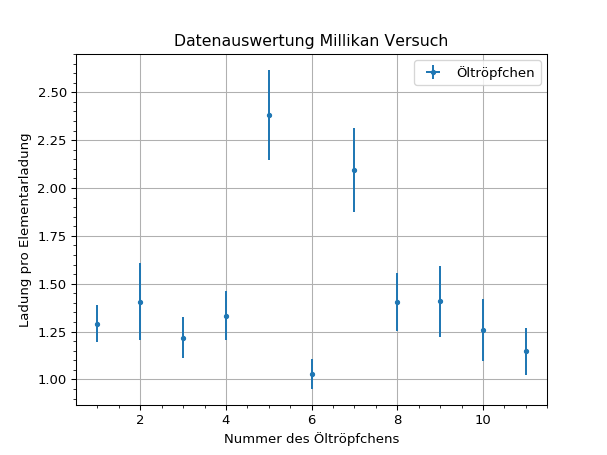

1.2917413628742518
1.0
1.4060070409141079
2.0
1.2175818283024773
3.0
1.3329962305597187
4.0
2.3809374198299498
5.0
1.0289048429707008
6.0
2.095210787127123
7.0
1.4056040021934968
8.0
1.407169331108704
9.0
1.2599883965956993
10.0
1.1462943695000813
11.0


In [76]:
%matplotlib notebook
plt.figure()
x_werte = np.linspace(1, 11, 11)
plt.grid()

y_werte = [0 for i in range(11)]
y_werte_err = [0 for i in range(11)]

for i in range(len(y_werte)):
    y_werte[i] = ladung_i[i]/e
    y_werte_err[i] = un_ladung_i[i]/e
    print(y_werte[i])
    print(x_werte[i])
    
plt.title("Datenauswertung Millikan Versuch")
plt.xlabel("Nummer des Öltröpfchens")
plt.ylabel("Ladung pro Elementarladung")
plt.minorticks_on()
plt.errorbar(x_werte, y_werte, xerr = 0, yerr = y_werte_err, fmt="o", markersize=3, label = "Öltröpfchen")
plt.legend()
plt.savefig("Datenauswertung Millikan.pdf")